# 06 · Mechanism gallery

The continuous mechanisms side by side on three hard conditional densities
`p(y | x)`: two branches (bimodal), noise that grows with `|x|`
(heteroscedastic), and a skewed noise.  For each one we plot the fitted
conditional density against the truth at three values of `x`, and compare
held-out log-likelihood and fit time.

- **NBN API:** `LinearGaussianMechanism`, `MDNMechanism`,
  `NormalizingFlowMechanism`, `ConditionalKDEMechanism`,
  `KNNConditionalMechanism`, `FlexCodeMechanism`; `fit`, `log_prob(per_node=True)`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"` (includes `zuko` for the flow), then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In every case `x ~ Uniform(-2, 2)` and the network is `x -> y`:

    bimodal          y | x ~ 0.5 N(sin(1.5 x) + 1, 0.25^2) + 0.5 N(sin(1.5 x) - 1, 0.25^2)
    heteroscedastic  y | x ~ N(0.8 x, (0.05 + 0.4 |x|)^2)
    skewed           y | x = 0.5 x + G,  G ~ Gamma(shape 2, scale 0.25 + 0.15 (x + 2))

In [1]:
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import (
    ConditionalKDEMechanism,
    FlexCodeMechanism,
    KNNConditionalMechanism,
    LinearGaussianMechanism,
    MDNMechanism,
    NeuralBayesianNetwork,
    seed_all,
)
from nbn.mechanisms import NormalizingFlowMechanism
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300")
GREY, INK = "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The three ground truths

Each truth has a sampler and an exact log-density `log p(y | x)`.

In [2]:
def normal_logpdf(y, mean, std):
    return -0.5 * ((y - mean) / std) ** 2 - torch.log(std * math.sqrt(2 * math.pi))


def gamma_scale(x):
    return 0.25 + 0.15 * (x + 2)


TRUTHS = {
    "bimodal": dict(
        sample=lambda x: torch.sin(1.5 * x) + torch.where(torch.rand_like(x) < 0.5, 1.0, -1.0)
        + 0.25 * torch.randn_like(x),
        logpdf=lambda y, x: torch.logsumexp(torch.stack([
            normal_logpdf(y, torch.sin(1.5 * x) + 1, torch.tensor(0.25)),
            normal_logpdf(y, torch.sin(1.5 * x) - 1, torch.tensor(0.25))]), 0) + math.log(0.5)),
    "heteroscedastic": dict(
        sample=lambda x: 0.8 * x + (0.05 + 0.4 * x.abs()) * torch.randn_like(x),
        logpdf=lambda y, x: normal_logpdf(y, 0.8 * x, 0.05 + 0.4 * x.abs())),
    "skewed": dict(
        sample=lambda x: 0.5 * x + torch.distributions.Gamma(2.0, 1 / gamma_scale(x)).sample(),
        logpdf=lambda y, x: torch.distributions.Gamma(2.0, 1 / gamma_scale(x)).log_prob(
            (y - 0.5 * x).clamp_min(1e-12)).where(y - 0.5 * x > 0, torch.tensor(-float("inf")))),
}


def make_data(name: str, n: int) -> dict:
    x = 4 * torch.rand(n, 1) - 2
    return {"x": x, "y": TRUTHS[name]["sample"](x)}


seed_all(0)
train = {name: make_data(name, 2000) for name in TRUTHS}
test = {name: make_data(name, 10_000) for name in TRUTHS}
for name in TRUTHS:
    ll = TRUTHS[name]["logpdf"](test[name]["y"], test[name]["x"]).mean()
    print(f"{name:16s} true held-out mean log-density {float(ll):+.3f}")

bimodal          true held-out mean log-density -0.716
heteroscedastic  true held-out mean log-density -0.432
skewed           true held-out mean log-density -0.939


## Fitting every continuous mechanism

The network is `x -> y`; `x` gets a linear-Gaussian root (its fit is not
scored) and `y` gets the mechanism under test.  Every mechanism uses its own
default training budget.  We record the time of the whole `fit` (the closed-form root
takes about a millisecond) and the held-out mean log-likelihood of `y`.

In [3]:
MECHANISMS = {
    "linear Gaussian": LinearGaussianMechanism,
    "MDN": MDNMechanism,
    "normalizing flow": NormalizingFlowMechanism,
    "conditional KDE": ConditionalKDEMechanism,
    "k-NN": KNNConditionalMechanism,
    "FlexCode": FlexCodeMechanism,
}
COLORS = dict(zip(MECHANISMS, (BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN)))

fitted, scores, seconds = {}, {}, {}
for name in TRUTHS:
    for mname, cls in MECHANISMS.items():
        seed_all(1)
        model = NeuralBayesianNetwork([("x", "y")], {"x": ("continuous", 1), "y": ("continuous", 1)},
                                      device=device)
        model.set_mechanism("x", LinearGaussianMechanism())
        model.set_mechanism("y", cls())
        start = time.perf_counter()
        model.fit(train[name], consolidate=False)
        seconds[name, mname] = time.perf_counter() - start
        with torch.no_grad():
            scores[name, mname] = float(model.log_prob(test[name], per_node=True)["y"].mean())
        fitted[name, mname] = model

true_ll = {name: float(TRUTHS[name]["logpdf"](test[name]["y"], test[name]["x"]).mean()) for name in TRUTHS}
print(f"{'mechanism':18s}" + "".join(f"{n:>24s}" for n in TRUTHS))
print(f"{'(truth)':18s}" + "".join(f"{true_ll[n]:+24.3f}" for n in TRUTHS))
for mname in MECHANISMS:
    print(f"{mname:18s}" + "".join(f"{scores[n, mname]:+15.3f} ({seconds[n, mname]:5.2f} s)"
                                   for n in TRUTHS))

mechanism                          bimodal         heteroscedastic                  skewed
(truth)                             -0.716                  -0.432                  -0.939
linear Gaussian            -1.526 ( 0.00 s)         -0.738 ( 0.00 s)         -1.196 ( 0.00 s)
MDN                        -0.739 ( 0.68 s)         -0.461 ( 0.34 s)         -0.959 ( 0.34 s)
normalizing flow           -0.780 ( 0.42 s)         -0.490 ( 0.40 s)         -0.973 ( 0.19 s)
conditional KDE            -0.960 ( 0.01 s)         -0.584 ( 0.01 s)         -1.021 ( 0.01 s)
k-NN                       -1.112 ( 0.01 s)         -0.482 ( 0.01 s)         -1.113 ( 0.01 s)
FlexCode                   -0.851 ( 0.22 s)         -0.589 ( 0.22 s)         -1.029 ( 0.22 s)


## Fitted against true conditional densities

For each truth, the fitted `p(y | x)` at `x = -1.5, 0, 1.5`; the dashed black
line is the true density.  Each panel has its own vertical scale.  The densities are computed with the mechanism's
`log_prob(y, parents)` on a grid of `y`.

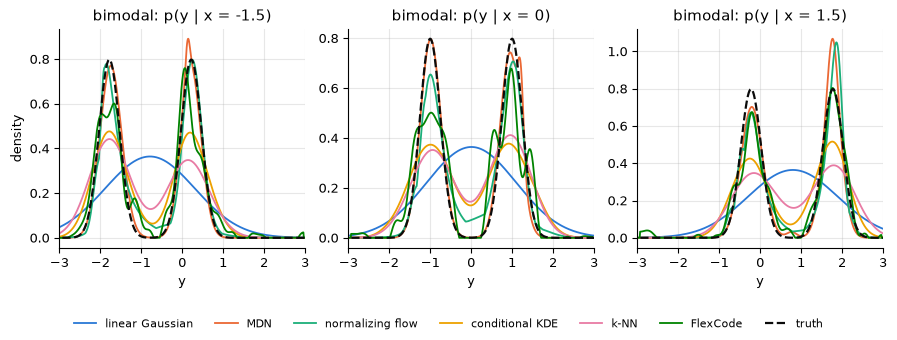

In [4]:
Y_GRID = torch.linspace(-3.5, 3.5, 701)
SLICES = (-1.5, 0.0, 1.5)


def slice_density(model, x0: float) -> torch.Tensor:
    mech = model.mechanisms["y"]
    parents = torch.full((len(Y_GRID), 1), x0, device=device)
    with torch.no_grad():
        return mech.log_prob(Y_GRID[:, None].to(device), parents).exp().reshape(-1).cpu()


def plot_truth(name: str, ylim):
    fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
    for ax, x0 in zip(axes, SLICES):
        for mname in MECHANISMS:
            ax.plot(to_numpy(Y_GRID), to_numpy(slice_density(fitted[name, mname], x0)),
                    color=COLORS[mname], lw=1.3, label=mname)
        true = TRUTHS[name]["logpdf"](Y_GRID, torch.full_like(Y_GRID, x0)).exp()
        ax.plot(to_numpy(Y_GRID), to_numpy(true), color=INK, lw=1.6, ls="--", label="truth")
        ax.set(xlabel="y", title=f"{name}: p(y | x = {x0:g})", xlim=ylim)
    axes[0].set_ylabel("density")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    fig.legend(handles, labels, frameon=False, fontsize=8, ncol=7, loc="lower center")
    plt.show()


plot_truth("bimodal", (-3.0, 3.0))

The linear-Gaussian mechanism puts one wide Gaussian between the two
branches (held-out log-likelihood -1.526, against -0.716 for the truth).  The
MDN, the flow and FlexCode find both branches at every `x`.  KDE and k-NN find
them too but blur them: with 2000 rows they average over a wide window.
FlexCode shows small wiggles, because it builds the density from a finite set
of basis functions.

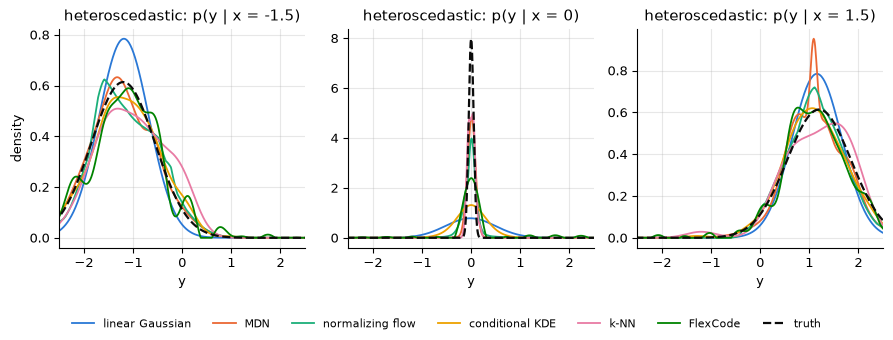

In [5]:
plot_truth("heteroscedastic", (-2.5, 2.5))

At `x = 0` the true noise sd is 0.05, so the density is a narrow spike with a
peak near 8.  No mechanism reaches it fully; the MDN comes closest.  The
linear-Gaussian mechanism has one noise level for every `x`: it is far too
wide at `x = 0` and too narrow at `x = ±1.5`.  k-NN adapts its window to the
data and does well on this truth (-0.482), close to the flow (-0.490) and the
MDN (-0.461).

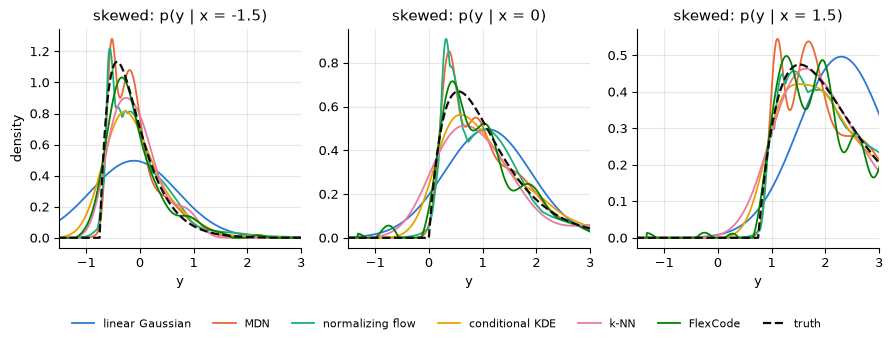

In [6]:
plot_truth("skewed", (-1.5, 3.0))

The true density starts sharply at `y = 0.5 x` (the gamma noise is never
negative) and has a long right tail.  The linear Gaussian is symmetric and puts
mass below the edge.  The MDN and the flow follow the sharp start best, with
some overshoot at the edge; KDE, k-NN and FlexCode round the edge off.

## Scores and fit times

Left: the gap between the true and the fitted held-out log-likelihood, which
is an estimate of `KL(true || fitted)` (lower is better; log scale).  Right:
the fit time of `y` on this machine (log scale).

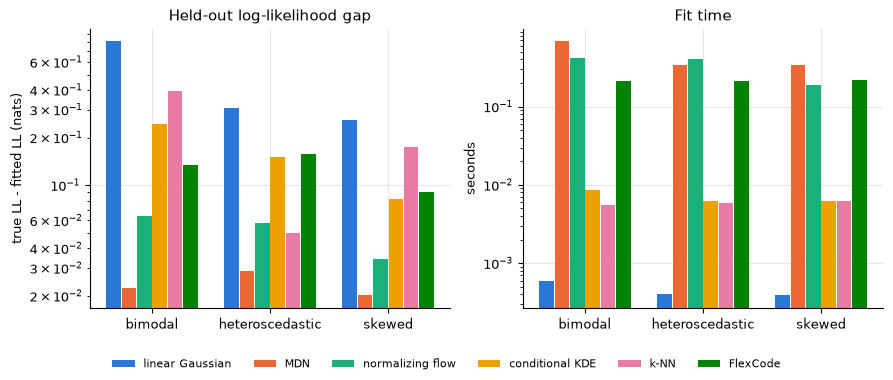

In [7]:
fig, (ax_k, ax_t) = plt.subplots(1, 2, figsize=(9, 3.8))
y_pos = np.arange(len(TRUTHS))
width = 0.13
for k, mname in enumerate(MECHANISMS):
    gaps = [max(true_ll[n] - scores[n, mname], 1e-3) for n in TRUTHS]
    times = [seconds[n, mname] for n in TRUTHS]
    offset = (k - (len(MECHANISMS) - 1) / 2) * width
    ax_k.bar(y_pos + offset, gaps, width * 0.95, color=COLORS[mname], label=mname)
    ax_t.bar(y_pos + offset, times, width * 0.95, color=COLORS[mname], label=mname)
for ax in (ax_k, ax_t):
    ax.set_xticks(y_pos, list(TRUTHS))
    ax.set_yscale("log")
ax_k.set(ylabel="true LL - fitted LL (nats)", title="Held-out log-likelihood gap")
ax_t.set(ylabel="seconds", title="Fit time")
handles, labels = ax_k.get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend(handles, labels, frameon=False, fontsize=8, ncol=6, loc="lower center")
plt.show()

- The MDN has the smallest gap on all three truths (0.02–0.03 nats), then
  the flow (0.03–0.06).
- The closed-form linear Gaussian fits in under a millisecond, but has the
  largest gap on every truth (0.26–0.81).
- KDE and k-NN fit in about 10 ms: they store the training sample and do their
  work when a density is evaluated.
- The gradient-trained mechanisms (MDN, flow, FlexCode) take a few tenths of
  a second with their default budgets.  Times change from machine to machine;
  read the orders of magnitude.